<a href="https://colab.research.google.com/github/Banulatha/Energy-consumption-prediction/blob/main/Energy_consumption_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
!pip -q install kagglehub

In [ ]:
import kagglehub
import os
import glob

# Download dataset
path = kagglehub.dataset_download(
    "patricklford/world-energy-consumption"
)

print("Dataset downloaded to:", path)

# Find CSV files
csv_files = glob.glob(path + "/**/*.csv", recursive=True)

print("CSV files found:", csv_files)

# Load the first CSV file
df = pd.read_csv(csv_files[0])

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

100%|██████████| 11.3k/11.3k [00:00<00:00, 14.2MB/s]

Extracting files...
Dataset downloaded to: /root/.cache/kagglehub/datasets/patricklford/world-energy-consumption/versions/1
CSV files found: ['/root/.cache/kagglehub/datasets/patricklford/world-energy-consumption/versions/1/World_Energy_By_Country_And_Region_1965_to_2023.csv']
Dataset shape: (111, 60)
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    2018    2019    2020  \
0    NaN    NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1   7.47   8.11  ...   14.43   14.47   14.34   14.54   14.72   14.64   13.76   
2   1.

In [ ]:
import pandas as pd
import numpy as np

# We already have df loaded from the correct path in the previous cell
# Remove any extra spaces from column names
df.columns = df.columns.str.strip()

country = "India"

# Find the row for India
india_row = df[df["Country"].astype(str).str.strip() == country]

if india_row.empty:
    raise ValueError(f"Country '{country}' not found in the dataset.")

# Melt the wide format dataset into a long format (years as rows)
year_cols = [col for col in df.columns if col.isdigit()]
data = india_row.melt(id_vars=["Country"], value_vars=year_cols, var_name="year", value_name="primary_energy_consumption")

# Convert columns to numeric
data["year"] = pd.to_numeric(data["year"], errors="coerce")
data["primary_energy_consumption"] = pd.to_numeric(data["primary_energy_consumption"], errors="coerce")

# Remove invalid years
data = data.dropna(subset=["year"])
data["year"] = data["year"].astype(int)

# Sort and clean
data = data.sort_values("year").reset_index(drop=True)

# Interpolate missing values if any
data = data.set_index("year")
data["primary_energy_consumption"] = data["primary_energy_consumption"].interpolate(method="index", limit_area="inside")
data = data.reset_index()

# Display results
print("Country:", country)
print("Number of yearly records:", len(data))
print("\nFirst 5 records:")
print(data.head())
print("\nLast 5 records:")
print(data.tail())
print("\nMissing values:")
print(data.isnull().sum())

Country: India
Number of yearly records: 59

First 5 records:
   year Country  primary_energy_consumption
0  1965   India                        2.23
1  1966   India                        2.30
2  1967   India                        2.37
3  1968   India                        2.53
4  1969   India                        2.81

Last 5 records:
    year Country  primary_energy_consumption
54  2019   India                       33.54
55  2020   India                       31.78
56  2021   India                       34.51
57  2022   India                       36.37
58  2023   India                       39.02

Missing values:
year                          0
Country                       0
primary_energy_consumption    0
dtype: int64


In [ ]:
# Convert the target column to a NumPy array
values = data[target].values.reshape(-1, 1)

# Chronological 80:20 split
split_index = int(len(values) * 0.8)

if split_index <= 5 or len(values) - split_index < 1:
    raise ValueError("Not enough yearly records for train-test splitting.")

# Fit scaler only on training data to prevent data leakage
scaler = MinMaxScaler()

scaler.fit(values[:split_index])
scaled_values = scaler.transform(values)

# Create sequences using the previous 5 years
X, y, target_indices = [], [], []

for i in range(5, len(scaled_values)):
    X.append(scaled_values[i-5:i])
    y.append(scaled_values[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

# Split sequences chronologically by target year
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42, 5, 1)
y_train shape: (42, 1)
X_test shape: (12, 5, 1)
y_test shape: (12, 1)


In [ ]:
model = Sequential([
    Input(shape=(5, 1)),
    LSTM(50, activation="tanh"),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - loss: 0.0868 - val_loss: 0.6143
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0691 - val_loss: 0.5284
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0575 - val_loss: 0.4628
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0477 - val_loss: 0.4056
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0385 - val_loss: 0.3491
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0303 - val_loss: 0.2948
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0231 - val_loss: 0.2424
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0169 - val_loss: 0.1924
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0121 - val_loss: 0.1467
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0090 - val_loss: 0.1067
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0074 - val_loss: 0.0735
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0073 - val_l

In [ ]:
# Predict test data
y_pred_scaled = model.predict(X_test)

# Convert predictions and actual values to original scale
y_pred = scaler.inverse_transform(y_pred_scaled)
y_actual = scaler.inverse_transform(y_test)

# Evaluation metrics
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("Model Evaluation Results")
print("------------------------")
print("MAE :", mae)
print("RMSE:", rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
Model Evaluation Results
------------------------
MAE : 1.5436633364359533
RMSE: 1.6563192001101041


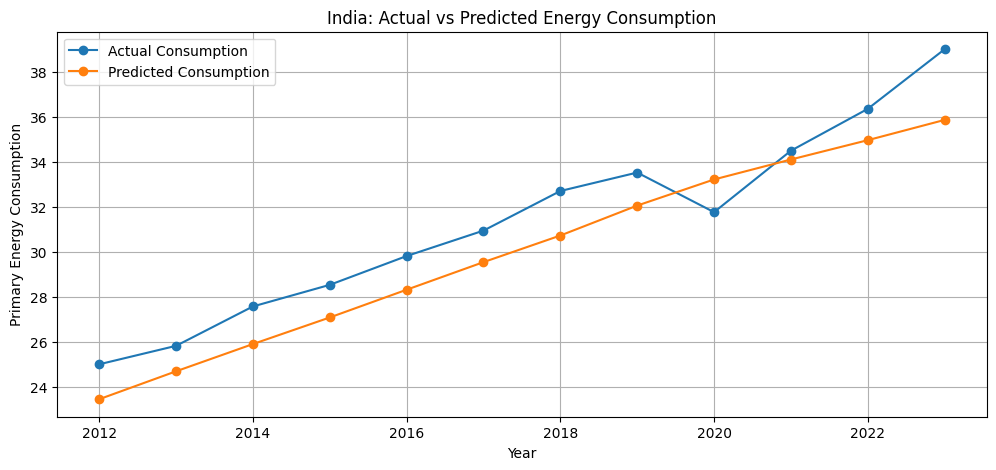

In [ ]:
test_years = data["year"].values[target_indices[test_mask]]

plt.figure(figsize=(12, 5))

plt.plot(
    test_years,
    y_actual.flatten(),
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    test_years,
    y_pred.flatten(),
    marker="o",
    label="Predicted Consumption"
)

plt.title("India: Actual vs Predicted Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Primary Energy Consumption")
plt.legend()
plt.grid(True)
plt.show()

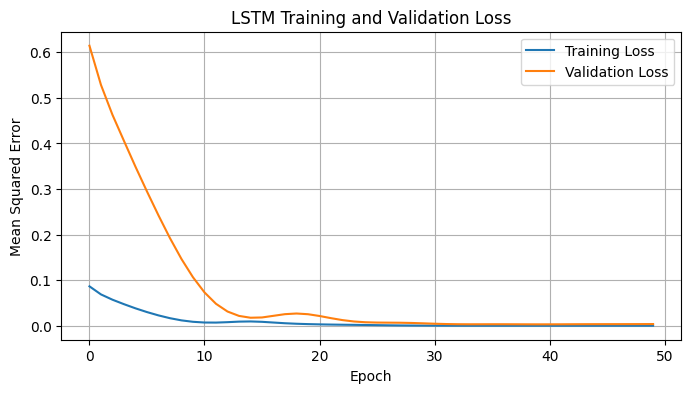

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Get the latest 5 years
last_five_years = scaled_values[-5:].reshape(1, 5, 1)

# Predict next-year consumption
next_scaled = model.predict(last_five_years)

# Convert to original scale
next_consumption = scaler.inverse_transform(next_scaled)[0, 0]

last_year = int(data["year"].max())
next_year = last_year + 1

print("Last recorded year:", last_year)
print("Predicted year:", next_year)
print("Predicted primary energy consumption:", next_consumption)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step
Last recorded year: 2023
Predicted year: 2024
Predicted primary energy consumption: 36.778885


In [ ]:
results = pd.DataFrame({
    "Year": test_years,
    "Actual Consumption": y_actual.flatten(),
    "Predicted Consumption": y_pred.flatten()
})

print(results.to_string(index=False))

print("\nFinal Evaluation")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))

 Year  Actual Consumption  Predicted Consumption
 2012               25.02              23.467905
 2013               25.84              24.708645
 2014               27.59              25.918497
 2015               28.55              27.100534
 2016               29.83              28.333179
 2017               30.96              29.558893
 2018               32.72              30.741816
 2019               33.54              32.072033
 2020               31.78              33.232525
 2021               34.51              34.119625
 2022               36.37              34.978615
 2023               39.02              35.878822

Final Evaluation
MAE : 1.5437
RMSE: 1.6563
